# Deeper exploratory analysis: demographics and preferences (Colab-ready)

Starts from **`prepared/cleaned_training_responses.csv`** (notebook 1). Builds on notebook 2’s finding that background fields are only weakly associated with choice — this notebook **describes the sample and preference patterns in detail** so the group can see the counts, not only the summary statistics.

**Important design note:** there is **no respondent id**. Every row is one *response*. The same person may appear more than once without us knowing. All counts below are **numbers of responses**, not unique people. Phrases like “how many have MBTI = I” mean “how many *rows* report I.”

**What this notebook covers:**
- Response counts by choice, comparison type, and every background field
- Joint profiles (e.g. gender × MBTI) so you can see which combinations dominate
- Preference for side A by each characteristic (with Wilson 95% CIs)
- Whether demographic gaps in P(A) differ for within-cat vs between-cat pairs
- A compact ranking of which background splits move P(A) the most (still small, as in notebook 2)
- A simple **logistic-regression baseline** on demographics + comparison type (Chapter 6 language)

**Course / report link:** The stratified rates and the logistic baseline supply the descriptive evidence and a first model-based check for the midterm report. Coefficients can later be compared with feature importances from trees/forests (Chapters 4–5) and with Bradley–Terry strengths that ignore demographics (Chapter 7).

**Bottom line of the whole notebook:** the sample is uneven across demographics (more men, more I, many “future pet = yes”); P(A) varies only a few points across groups (largest span ≈ 5 points for MBTI); notebook 2’s weak Cramér’s V is visible here in the raw counts. Use these tables for description and reporting — not as strong predictors.


## 0. Setup (Colab or local)

**Purpose:** locate the cleaned CSV from notebook 1, create figure folders, and define shared constants.

**What this section does:**
- Searches common paths for `prepared/cleaned_training_responses.csv`
- Verifies columns produced by notebook 1 (`chose_a`, `demo_complete`, background fields)
- Defines ordered display levels for each demographic field
- Provides Wilson intervals for proportion plots

**Bottom line:** if the cleaned file is missing, run notebook 1 first (or upload `cleaned_training_responses.csv` into `prepared/`).

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from IPython.display import display
except ImportError:
    def display(x):
        print(x)


def find_cleaned_path() -> Path:
    candidates = [
        Path.cwd() / "prepared" / "cleaned_training_responses.csv",
        Path.cwd() / "cleaned_training_responses.csv",
        Path.cwd().parent / "prepared" / "cleaned_training_responses.csv",
        Path("/content") / "prepared" / "cleaned_training_responses.csv",
        Path("/content") / "cleaned_training_responses.csv",
        Path("/content/drive/MyDrive") / "prepared" / "cleaned_training_responses.csv",
        Path("/home/workdir/artifacts") / "prepared" / "cleaned_training_responses.csv",
    ]
    for p in candidates:
        if p.is_file():
            return p
    raise FileNotFoundError(
        "Could not find prepared/cleaned_training_responses.csv. "
        "Run notebook 1 first, or upload the cleaned CSV into a prepared/ folder."
    )


CLEANED_PATH = find_cleaned_path()
FIG_DIR = Path.cwd() / "model-checks" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

DEMO_COLS = [
    "gender",
    "pet_history",
    "pet_care",
    "pet_contact",
    "future_pet",
    "mbti_ie",
]
LEVELS = {
    "gender": ["woman", "man"],
    "pet_history": ["current", "past", "never"],
    "pet_care": ["current_regular", "past_regular", "occasionally", "never"],
    "pet_contact": ["daily", "often", "sometimes", "rarely", "never"],
    "future_pet": ["yes", "unsure", "no"],
    "mbti_ie": ["E", "I", "unknown"],
}
REQUIRED_COLS = [
    "train_row_id",
    "choice",
    "comparison_type",
    "chose_a",
    "demo_complete",
    *DEMO_COLS,
]


def wilson_interval(successes, n, z=1.96):
    successes = float(successes)
    n = float(n)
    if n <= 0:
        return np.nan, np.nan
    p = successes / n
    den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    margin = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - margin, centre + margin


def count_table(series, levels=None):
    vc = series.value_counts(dropna=False)
    if levels is not None:
        vc = vc.reindex(levels, fill_value=0)
    out = pd.DataFrame({"n_responses": vc, "share": vc / vc.sum()})
    return out


def preference_by(df, col, levels=None):
    rows = []
    ordered = levels if levels is not None else list(df[col].dropna().unique())
    for level in ordered:
        sub = df[df[col] == level]
        n = len(sub)
        k = int(sub["chose_a"].sum()) if n else 0
        rate = k / n if n else np.nan
        low, high = wilson_interval(k, n) if n else (np.nan, np.nan)
        rows.append(
            {
                col: level,
                "n_responses": n,
                "n_chose_a": k,
                "n_chose_b": n - k,
                "share_chose_a": rate,
                "low_95": low,
                "high_95": high,
            }
        )
    return pd.DataFrame(rows)


train = pd.read_csv(CLEANED_PATH)
missing = [c for c in REQUIRED_COLS if c not in train.columns]
if missing:
    raise ValueError(
        f"Cleaned file is missing columns {missing}. "
        "Re-run notebook 1 so derived fields exist."
    )
train["demo_complete"] = train["demo_complete"].astype(bool)
train["chose_a"] = train["chose_a"].astype(int)
complete = train[train["demo_complete"]].copy()

print("CLEANED_PATH:", CLEANED_PATH.resolve())
print("FIG_DIR:", FIG_DIR.resolve())
print(f"all rows: {len(train):,}")
print(f"demo_complete rows: {len(complete):,}")
print(f"background missing: {int((~train['demo_complete']).sum()):,}")

CLEANED_PATH: /content/cleaned_training_responses.csv
FIG_DIR: /content/model-checks/figures
all rows: 24,896
demo_complete rows: 24,388
background missing: 508


### Optional: upload cleaned CSV in Colab

**When to use:** only if setup could not find the cleaned file.

**Bottom line:** skip when setup already printed a valid `CLEANED_PATH`.

In [ ]:
# Uncomment in Google Colab if needed:
# from google.colab import files
# from pathlib import Path
# uploaded = files.upload()  # select cleaned_training_responses.csv
# Path("prepared").mkdir(exist_ok=True)
# if "cleaned_training_responses.csv" in uploaded:
#     Path("prepared/cleaned_training_responses.csv").write_bytes(
#         uploaded["cleaned_training_responses.csv"]
#     )
#     print("Uploaded — re-run the setup cell.")

## 1. Overall choice counts

**This section answers:** *How many responses chose A vs B, and does that differ by comparison type?*

**What this analysis is testing:** the raw counts behind the ~52% side-A rate from notebooks 1–2.

**How to read the result (this dataset):**
- A ≈ **12,921** responses (51.9%); B ≈ **11,975** (48.1%)
- Between-cats dominate the sample (~21.9k vs ~3.0k within-cat); P(A) is nearly the same in both (~0.52)

**Bottom line:** counts confirm a mild A majority. Comparison type changes volume far more than it changes the side rate.

In [ ]:
choice_counts = count_table(train["choice"], levels=["A", "B"])
choice_counts.index.name = "choice"
display(choice_counts.round(4))

type_counts = count_table(train["comparison_type"], levels=["within_cat", "between_cats"])
type_counts.index.name = "comparison_type"
display(type_counts.round(4))

cross = (
    pd.crosstab(train["comparison_type"], train["choice"], margins=True)
    .reindex(index=["within_cat", "between_cats", "All"])
    .reindex(columns=["A", "B", "All"])
)
display(cross)

by_type = (
    train.groupby("comparison_type")["chose_a"]
    .agg(n_responses="size", n_chose_a="sum", share_chose_a="mean")
    .reindex(["within_cat", "between_cats"])
)
by_type["n_chose_b"] = by_type["n_responses"] - by_type["n_chose_a"]
display(by_type[["n_responses", "n_chose_a", "n_chose_b", "share_chose_a"]].round(4))

print(f"overall P(A) = {train['chose_a'].mean():.4f}")

,n_responses,share
choice,,
A,12921,0.519
B,11975,0.481


,n_responses,share
comparison_type,,
within_cat,3003,0.1206
between_cats,21893,0.8794


choice,A,B,All
comparison_type,,,
within_cat,1544,1459,3003
between_cats,11377,10516,21893
All,12921,11975,24896


,n_responses,n_chose_a,n_chose_b,share_chose_a
comparison_type,,,,
within_cat,3003,1544,1459,0.5142
between_cats,21893,11377,10516,0.5197


overall P(A) = 0.5190


## 2. Response counts by each background field

**This section answers:** *How many responses fall in each demographic category?*

**What this analysis is testing:** sample composition on rows with complete background data only (`demo_complete`). Example: how many responses report MBTI = I vs E vs unknown.

**How to read the result (this dataset, n = 24,388):**
- **Gender:** man ~14.0k (57%), woman ~10.4k (43%)
- **Pet history:** never ~38%, current ~36%, past ~26%
- **Future pet:** yes ~70% — the most skewed single field
- **MBTI I/E:** I ~14.0k (57%), E ~6.3k (26%), unknown ~4.0k (17%)

**Bottom line:** the training responses are not a balanced demographic grid. Descriptive claims should weight common groups more carefully; rare cells (e.g. pet_contact = never) have wider uncertainty later.


=== gender (complete background rows only) ===


,n_responses,share
gender,,
woman,10390,0.426
man,13998,0.574



=== pet_history (complete background rows only) ===


,n_responses,share
pet_history,,
current,8650,0.3547
past,6423,0.2634
never,9315,0.3820



=== pet_care (complete background rows only) ===


...

,n_responses,share
pet_contact,,
daily,5084,0.2085
often,4891,0.2005
sometimes,5793,0.2375
rarely,7566,0.3102
never,1054,0.0432



=== future_pet (complete background rows only) ===


,n_responses,share
future_pet,,
yes,17172,0.7041
unsure,4834,0.1982
no,2382,0.0977



=== mbti_ie (complete background rows only) ===


,n_responses,share
mbti_ie,,
E,6346,0.2602
I,14000,0.5741
unknown,4042,0.1657


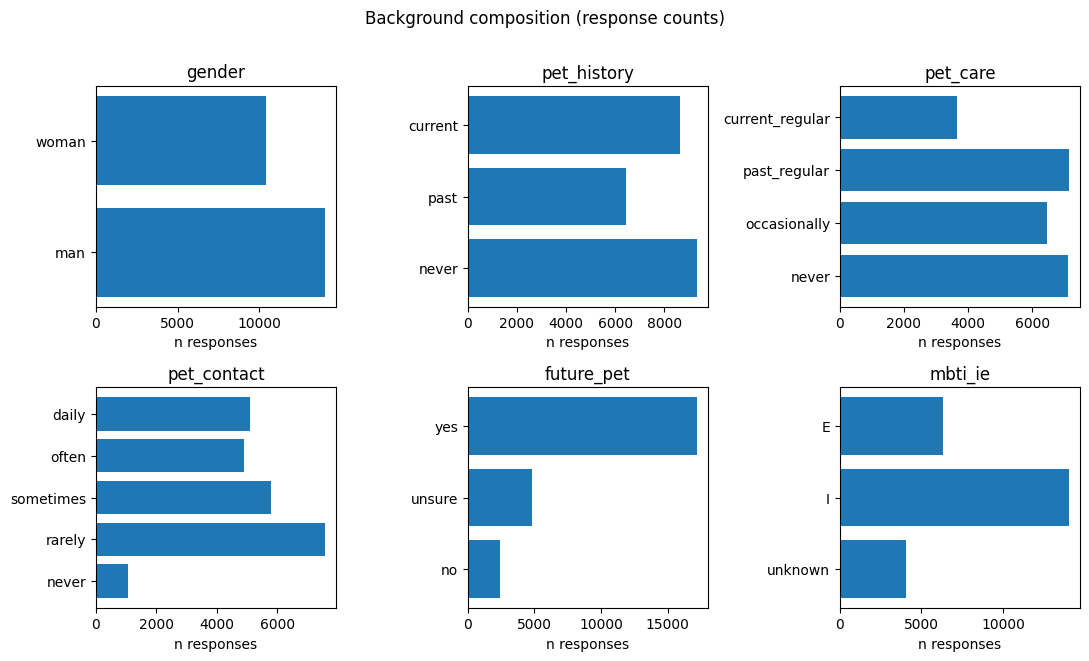

In [ ]:
for col in DEMO_COLS:
    print(f"\n=== {col} (complete background rows only) ===")
    tab = count_table(complete[col], levels=LEVELS[col])
    tab.index.name = col
    display(tab.round(4))

fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))
axes = axes.ravel()
for ax, col in zip(axes, DEMO_COLS):
    tab = count_table(complete[col], levels=LEVELS[col])
    ax.barh(range(len(tab)), tab["n_responses"].to_numpy(), color="C0")
    ax.set_yticks(range(len(tab)), [str(i) for i in tab.index])
    ax.set_xlabel("n responses")
    ax.set_title(col)
    ax.invert_yaxis()
fig.suptitle("Background composition (response counts)", y=1.01)
fig.tight_layout()
fig.savefig(FIG_DIR / "nb3_background_counts.png", bbox_inches="tight")
plt.show()

## 3. Joint demographic profiles

**This section answers:** *Which combinations of characteristics show up most often?*

**What this analysis is testing:** dependence among background fields as *counts* (notebook 2 already reported high Cramér’s V between pet fields). Useful for reporting “typical respondent profiles” in the sample of responses.

**How to read the result (this dataset):**
- About **69** distinct full six-field profiles
- Top profile is on the order of **1,600** responses (e.g. man | never pets | never care | rarely contact | future yes | I)
- Gender × MBTI and pet_history × pet_care cross-tabs show the mass of the sample clearly

**Bottom line:** a handful of profiles dominate. When you compare preferences “between groups,” some groups are much larger than others — always report **n** next to rates.

In [ ]:
profile = complete[DEMO_COLS].astype(str).agg(" | ".join, axis=1)
top_profiles = profile.value_counts().head(20).rename("n_responses")
display(top_profiles.to_frame())
print("unique full profiles:", profile.nunique())
print("share in top 5 profiles:", round(top_profiles.head(5).sum() / len(complete), 3))
print("share in top 20 profiles:", round(top_profiles.sum() / len(complete), 3))

print("\nGender × MBTI (response counts)")
g_mbti = pd.crosstab(complete["gender"], complete["mbti_ie"]).reindex(
    index=LEVELS["gender"], columns=LEVELS["mbti_ie"]
)
display(g_mbti)
display((g_mbti.div(g_mbti.values.sum())).round(3))

print("Pet history × pet care (response counts)")
h_care = pd.crosstab(complete["pet_history"], complete["pet_care"]).reindex(
    index=LEVELS["pet_history"], columns=LEVELS["pet_care"]
)
display(h_care)

,n_responses
man | never | never | rarely | yes | I,1600
woman | never | never | rarely | yes | I,1070
woman | current | current_regular | daily | yes | I,948
man | never | never | never | yes | unknown,646
man | current | occasionally | sometimes | yes | I,645
man | current | occasionally | often | yes | I,629
man | past | past_regular | sometimes | yes | I,627
man | past | past_regular | daily | yes | I,501
man | current | past_regular | often | yes | I,498
man | never | never | rarely | unsure | E,412


unique full profiles: 69
share in top 5 profiles: 0.201
share in top 20 profiles: 0.46

Gender × MBTI (response counts)


mbti_ie,E,I,unknown
gender,,,
woman,3013,6220,1157
man,3333,7780,2885


mbti_ie,E,I,unknown
gender,,,
woman,0.124,0.255,0.047
man,0.137,0.319,0.118


Pet history × pet care (response counts)


pet_care,current_regular,past_regular,occasionally,never
pet_history,,,,
current,3134,2704,2812,0
past,0,4331,2092,0
never,520,100,1566,7129


## 4. Preference for A by each characteristic

**This section answers an important question:** *Do responses from different demographic groups choose A at different rates?*

**What this analysis is testing:** for each background field, counts of A vs B and P(A) with Wilson 95% CIs. This is the detailed view behind notebook 2’s small Cramér’s V values.

**How to read the result (this dataset):**
- Most groups sit near the overall **0.517** complete-row P(A)
- **Largest single-field span** is MBTI: E ≈ 0.550 vs I ≈ 0.497 (about **5 points**)
- Gender barely moves P(A) (~1 point or less)
- Pet-related fields move P(A) by roughly 2–4 points across their extremes

**Bottom line:** preferences differ slightly by characteristic, but **no demographic split is large**. MBTI I/E is the biggest one-dimensional gap and still modest. Demographics describe the sample more than they drive the choice.

P(A) on complete rows: 0.5172

=== preference by gender ===


,gender,n_responses,n_chose_a,n_chose_b,share_chose_a,low_95,high_95
0,woman,10390,5423,4967,0.5219,0.5123,0.5315
1,man,13998,7191,6807,0.5137,0.5054,0.5220



=== preference by pet_history ===


,pet_history,n_responses,n_chose_a,n_chose_b,share_chose_a,low_95,high_95
0,current,8650,4277,4373,0.4945,0.4839,0.5050
1,past,6423,3377,3046,0.5258,0.5135,0.5380
2,never,9315,4960,4355,0.5325,0.5223,0.5426



=== preference by pet_care ===


...

,future_pet,n_responses,n_chose_a,n_chose_b,share_chose_a,low_95,high_95
0,yes,17172,9057,8115,0.5274,0.5200,0.5349
1,unsure,4834,2394,2440,0.4952,0.4812,0.5093
2,no,2382,1163,1219,0.4882,0.4682,0.5083



=== preference by mbti_ie ===


,mbti_ie,n_responses,n_chose_a,n_chose_b,share_chose_a,low_95,high_95
0,E,6346,3493,2853,0.5504,0.5382,0.5626
1,I,14000,6959,7041,0.4971,0.4888,0.5054
2,unknown,4042,2162,1880,0.5349,0.5195,0.5502



Ranked by how much P(A) spans across groups


,min_share_a,max_share_a,rate_span,highest_group,lowest_group
field,,,,,
mbti_ie,0.4971,0.5504,0.0534,E,I
future_pet,0.4882,0.5274,0.0392,yes,no
pet_history,0.4945,0.5325,0.0380,never,current
pet_care,0.4992,0.5332,0.0339,never,occasionally
pet_contact,0.5049,0.5276,0.0227,rarely,sometimes
gender,0.5137,0.5219,0.0082,woman,man


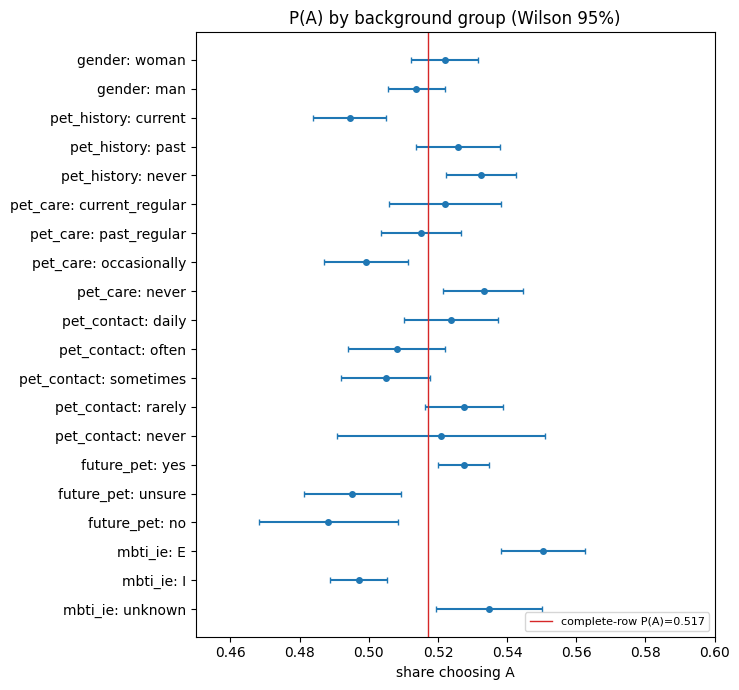

In [ ]:
overall_complete_p = complete["chose_a"].mean()
print(f"P(A) on complete rows: {overall_complete_p:.4f}")

pref_tables = {}
span_rows = []
for col in DEMO_COLS:
    tab = preference_by(complete, col, levels=LEVELS[col])
    pref_tables[col] = tab
    print(f"\n=== preference by {col} ===")
    display(tab.round(4))
    span = tab["share_chose_a"].max() - tab["share_chose_a"].min()
    span_rows.append(
        {
            "field": col,
            "min_share_a": tab["share_chose_a"].min(),
            "max_share_a": tab["share_chose_a"].max(),
            "rate_span": span,
            "highest_group": tab.loc[tab["share_chose_a"].idxmax(), col],
            "lowest_group": tab.loc[tab["share_chose_a"].idxmin(), col],
        }
    )

span_summary = pd.DataFrame(span_rows).set_index("field").sort_values("rate_span", ascending=False)
print("\nRanked by how much P(A) spans across groups")
display(span_summary.round(4))

# Forest-style plot of all group rates
plot_rows = []
for col in DEMO_COLS:
    tab = pref_tables[col]
    for _, r in tab.iterrows():
        plot_rows.append(
            {
                "label": f"{col}: {r[col]}",
                "rate": r["share_chose_a"],
                "low": r["low_95"],
                "high": r["high_95"],
                "n": r["n_responses"],
            }
        )
rates = pd.DataFrame(plot_rows).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 7.0))
y = np.arange(len(rates))
ax.errorbar(
    rates["rate"],
    y,
    xerr=[rates["rate"] - rates["low"], rates["high"] - rates["rate"]],
    fmt="o",
    color="C0",
    capsize=2,
    markersize=4,
)
ax.axvline(overall_complete_p, color="C3", lw=1, label=f"complete-row P(A)={overall_complete_p:.3f}")
ax.set_yticks(y, rates["label"])
ax.set_xlabel("share choosing A")
ax.set_xlim(0.45, 0.60)
ax.set_title("P(A) by background group (Wilson 95%)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "nb3_preference_by_group.png", bbox_inches="tight")
plt.show()

## 5. Preference by characteristic × comparison type

**This section answers:** *Does a demographic gap in P(A) look different for within-cat vs between-cat pairs?*

**What this analysis is testing:** whether any group’s side preference is specific to same-cat photo pairs versus different-cat pairs.

**How to read the result:** each table shows n and P(A) by group inside each comparison type. Look for gaps that **flip direction** or **shrink/grow** sharply across types — those would be more interesting than a uniform 2–3 point shift.

**Bottom line (this dataset):** gaps stay small in both comparison types. Nothing suggests a large demographic effect hidden inside only within-cat or only between-cat rows.

In [ ]:
for col in DEMO_COLS:
    rows = []
    for ctype in ["within_cat", "between_cats"]:
        sub = complete[complete["comparison_type"] == ctype]
        tab = preference_by(sub, col, levels=LEVELS[col])
        tab.insert(0, "comparison_type", ctype)
        rows.append(tab)
    stacked = pd.concat(rows, ignore_index=True)
    print(f"\n=== {col} × comparison_type ===")
    display(
        stacked.pivot_table(
            index=col,
            columns="comparison_type",
            values=["n_responses", "share_chose_a"],
            aggfunc="first",
        ).reindex(LEVELS[col]).round(4)
    )


=== gender × comparison_type ===


n_responses            share_chose_a           
comparison_type between_cats within_cat  between_cats within_cat
gender                                                          
woman                   9136       1254        0.5221     0.5207
man                    12298       1700        0.5147     0.5065


=== pet_history × comparison_type ===


n_responses            share_chose_a           
comparison_type between_cats within_cat  between_cats within_cat
pet_history                                                     
current                 7512       1138        0.4932     0.5026
past                    5663        760        0.5315     0.4829
never                   8259       1056        0.5309     0.5445


=== pet_care × comparison_type ===


...

n_responses            share_chose_a           
comparison_type between_cats within_cat  between_cats within_cat
pet_contact                                                     
daily                   4441        643        0.5256     0.5117
often                   4306        585        0.5088     0.5026
sometimes               5075        718        0.5080     0.4833
rarely                  6688        878        0.5263     0.5376
never                    924        130        0.5162     0.5538


=== future_pet × comparison_type ===


n_responses            share_chose_a           
comparison_type between_cats within_cat  between_cats within_cat
future_pet                                                      
yes                    15042       2130        0.5289     0.5174
unsure                  4314        520        0.4972     0.4788
no                      2078        304        0.4812     0.5362


=== mbti_ie × comparison_type ===


n_responses            share_chose_a           
comparison_type between_cats within_cat  between_cats within_cat
mbti_ie                                                         
E                       5535        811        0.5492     0.5586
I                      12329       1671        0.4986     0.4859
unknown                 3570        472        0.5359     0.5275

## 6. Two-way preference slices (examples)

**This section answers:** *Within a demographic cross (e.g. gender × MBTI), how many responses chose A vs B?*

**What this analysis is testing:** whether combining two fields reveals a pocket with a much higher or lower P(A). We focus on gender × MBTI and pet_history × future_pet as readable examples; the same pattern can be repeated for other pairs.

**How to read the result (this dataset):** cell-level P(A) still clusters around 0.50–0.55. Some cells are large (man × I); some are smaller (woman × E). Large cells dominate any overall impression.

**Bottom line:** two-way slices do not uncover a hidden strong demographic driver. They are useful for transparent reporting (“in this subgroup of responses, n and P(A) were …”).

Gender × MBTI — number of responses


mbti_ie,E,I,unknown
gender,,,
woman,3013,6220,1157
man,3333,7780,2885


Gender × MBTI — number choosing A


mbti_ie,E,I,unknown
gender,,,
woman,1731,3103,589
man,1762,3856,1573


Gender × MBTI — share choosing A


...


Pet history × future_pet — number of responses


future_pet,yes,unsure,no
pet_history,,,
current,6749,1580,321
past,4472,1325,626
never,5951,1929,1435


Pet history × future_pet — share choosing A


future_pet,yes,unsure,no
pet_history,,,
current,0.5161,0.4589,0.2150
past,0.5273,0.5230,0.5208
never,0.5404,0.5060,0.5352


/tmp/ipykernel_2368/392677912.py:40: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


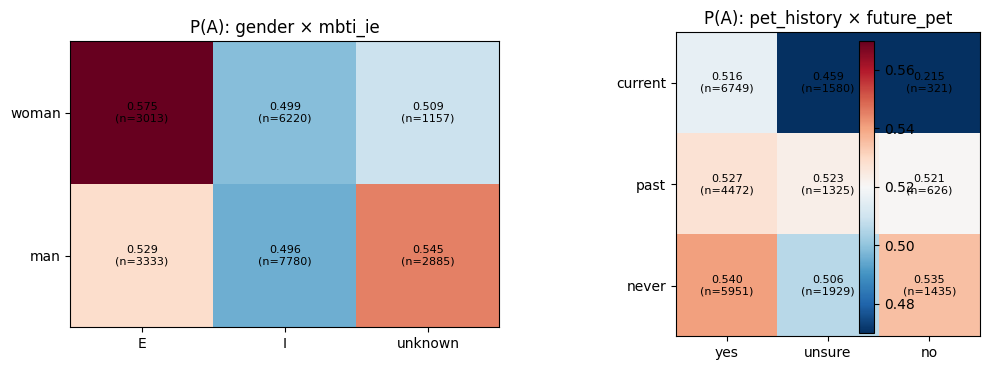

In [ ]:
def two_way_preference(df, row_col, col_col):
    ct_n = pd.crosstab(df[row_col], df[col_col])
    ct_a = pd.crosstab(df[row_col], df[col_col], values=df["chose_a"], aggfunc="sum")
    ct_n = ct_n.reindex(index=LEVELS[row_col], columns=LEVELS[col_col])
    ct_a = ct_a.reindex(index=LEVELS[row_col], columns=LEVELS[col_col])
    rate = ct_a / ct_n
    return ct_n, ct_a, rate


print("Gender × MBTI — number of responses")
n1, a1, r1 = two_way_preference(complete, "gender", "mbti_ie")
display(n1)
print("Gender × MBTI — number choosing A")
display(a1)
print("Gender × MBTI — share choosing A")
display(r1.round(4))

print("\nPet history × future_pet — number of responses")
n2, a2, r2 = two_way_preference(complete, "pet_history", "future_pet")
display(n2)
print("Pet history × future_pet — share choosing A")
display(r2.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
im0 = axes[0].imshow(r1.to_numpy(dtype=float), cmap="RdBu_r", vmin=0.47, vmax=0.57)
axes[0].set_xticks(range(len(r1.columns)), r1.columns)
axes[0].set_yticks(range(len(r1.index)), r1.index)
axes[0].set_title("P(A): gender × mbti_ie")
for i in range(r1.shape[0]):
    for j in range(r1.shape[1]):
        axes[0].text(j, i, f"{r1.iloc[i, j]:.3f}\n(n={int(n1.iloc[i, j])})", ha="center", va="center", fontsize=8)
im1 = axes[1].imshow(r2.to_numpy(dtype=float), cmap="RdBu_r", vmin=0.47, vmax=0.57)
axes[1].set_xticks(range(len(r2.columns)), r2.columns)
axes[1].set_yticks(range(len(r2.index)), r2.index)
axes[1].set_title("P(A): pet_history × future_pet")
for i in range(r2.shape[0]):
    for j in range(r2.shape[1]):
        axes[1].text(j, i, f"{r2.iloc[i, j]:.3f}\n(n={int(n2.iloc[i, j])})", ha="center", va="center", fontsize=8)
fig.colorbar(im1, ax=axes.ravel().tolist(), fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "nb3_two_way_preference.png", bbox_inches="tight")
plt.show()

## 7. Blank-background rows vs complete (reminder)

**This section answers:** *How do the 508 rows without background compare on choice counts?*

**What this analysis is testing:** a short count-level reminder of notebook 2’s result, so this demographic notebook stays consistent about who is in each table.

**How to read the result:** blank rows choose A more often (~60% vs ~52%). All sections 2–6 used **complete** rows only.

**Bottom line:** demographic tables above describe 24,388 responses. Overall project rates that include blanks will be slightly higher on A.

In [ ]:
rows = []
for label, mask in [
    ("background missing", ~train["demo_complete"]),
    ("background complete", train["demo_complete"]),
    ("all rows", slice(None)),
]:
    sub = train.loc[mask]
    k = int(sub["chose_a"].sum())
    n = len(sub)
    low, high = wilson_interval(k, n)
    rows.append(
        {
            "subset": label,
            "n_responses": n,
            "n_chose_a": k,
            "n_chose_b": n - k,
            "share_chose_a": k / n,
            "low_95": low,
            "high_95": high,
        }
    )
display(pd.DataFrame(rows).set_index("subset").round(4))

,n_responses,n_chose_a,n_chose_b,share_chose_a,low_95,high_95
subset,,,,,,
background missing,508,307,201,0.6043,0.5612,0.6459
background complete,24388,12614,11774,0.5172,0.5109,0.5235
all rows,24896,12921,11975,0.5190,0.5128,0.5252


## 8. Simple logistic baseline (course link — Chapter 6)

**This section answers:** *After accounting for comparison type, do the demographic fields still shift the log-odds of choosing A?*

**What this analysis is testing:** a linear score on dummy-coded demographics + `comparison_type`, mapped to a probability by the logistic (sigmoid) link — the model introduced in Chapter 6. We fit on **complete-background** rows only, report coefficients (log-odds), and give a rough in-sample accuracy. This is a *baseline*, not a final predictive model; no regularisation path or proper pair-aware cross-validation is run here.

**How to read the result:** coefficients near zero and a tiny lift over the majority-class baseline confirm notebook 2’s weak associations. The model is still useful for the report: it states the same story in the language of the course and supplies a reference against which later Bradley–Terry or forest models can be compared.

**Bottom line:** demographics + comparison type give only a marginal improvement over always predicting the majority side. Cat/image structure (notebook 2) remains the stronger signal.


In [ ]:
# Lightweight logistic baseline (Chapter 6). Uses sklearn if available, else a pure-numpy IRLS fallback is not needed.
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, log_loss

model_df = complete.copy()
feature_cols = DEMO_COLS + ["comparison_type"]
X = model_df[feature_cols]
y = model_df["chose_a"].astype(int)

pre = ColumnTransformer(
    [("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), feature_cols)],
    remainder="drop",
)
clf = Pipeline(
    [
        ("pre", pre),
        ("logit", LogisticRegression(max_iter=1000, solver="lbfgs")),
    ]
)
clf.fit(X, y)

prob = clf.predict_proba(X)[:, 1]
pred = (prob >= 0.5).astype(int)
acc = accuracy_score(y, pred)
ll = log_loss(y, prob)
majority = max(y.mean(), 1 - y.mean())

print(f"n = {len(y):,}  (complete-background rows only)")
print(f"Majority-class accuracy: {majority:.4f}")
print(f"Logistic in-sample accuracy: {acc:.4f}")
print(f"Logistic in-sample log-loss: {ll:.4f}")

# Coefficients on the dummy scale (log-odds)
ohe = clf.named_steps["pre"].named_transformers_["cat"]
names = ohe.get_feature_names_out(feature_cols)
coefs = clf.named_steps["logit"].coef_.ravel()
intercept = float(clf.named_steps["logit"].intercept_[0])
coef_table = (
    pd.DataFrame({"feature": names, "coef_log_odds": coefs})
    .assign(odds_ratio=lambda d: np.exp(d["coef_log_odds"]))
    .sort_values("coef_log_odds", key=lambda s: s.abs(), ascending=False)
)
print(f"\nIntercept (log-odds): {intercept:.4f}")
display(coef_table.round(4))

print(
    "\nNote: this is an in-sample baseline only. For the report, re-fit inside a "
    "pair-aware or image-aware split (see notebook 2) and consider regularisation (Chapter 3)."
)


n = 24,388  (complete-background rows only)
Majority-class accuracy: 0.5172
Logistic in-sample accuracy: 0.5340
Logistic in-sample log-loss: 0.6896

Intercept (log-odds): 0.0027


,feature,coef_log_odds,odds_ratio
11,future_pet_yes,0.2424,1.2744
12,mbti_ie_I,-0.2232,0.8000
1,pet_history_never,0.1909,1.2104
6,pet_contact_never,-0.1499,0.8608
4,pet_care_occasionally,-0.1197,0.8872
2,pet_history_past,0.1133,1.1200
3,pet_care_never,-0.1063,0.8992
5,pet_care_past_regular,-0.0774,0.9255
8,pet_contact_rarely,0.0634,1.0654
10,future_pet_unsure,0.0457,1.0468



Note: this is an in-sample baseline only. For the report, re-fit inside a pair-aware or image-aware split (see notebook 2) and consider regularisation (Chapter 3).


## 9. Reading the numbers

**Purpose:** connect detailed counts to notebooks 1–2 and to modeling choices.

| Finding | Detail |
|---------|--------|
| Choice counts | A 12,921 / B 11,975 on all rows; mild A majority |
| Sample shape | More man than woman; more I than E; future_pet heavily “yes” |
| Profiles | ~69 full profiles; top few account for a large share of responses |
| Preference gaps | Largest one-field span ≈ 5 points (MBTI E > I); most gaps 1–4 points |
| Two-way slices | No cell with a dramatically different P(A) |
| Blanks | 508 rows at ~60% A — excluded from demographic tables, included in overall rates |
| Logistic baseline | Accuracy only marginally above majority class; coefficients small — demographics alone are weak predictors |

**Link to notebook 2 and to the course:** small rate spans and weak logistic coefficients are the same story as Cramér’s V ≲ 0.05. For the midterm report, treat demographics as useful for *description and stratification*, and put the main modelling effort on cat/image structure (Bradley–Terry, forests with image or cat features). Any predictive claim should use a split that respects repeated pairs or images.


In [ ]:
print("Notebook 3 summary")
print(f"  all responses:              {len(train):,}")
print(f"  complete background:        {len(complete):,}")
print(f"  P(A) all rows:              {train['chose_a'].mean():.4f}")
print(f"  P(A) complete rows:         {complete['chose_a'].mean():.4f}")
print("  rate span by field (complete rows):")
for field, row in span_summary.iterrows():
    print(
        f"    {field:12} span={row.rate_span:.3f}  "
        f"highest={row.highest_group} ({row.max_share_a:.3f})  "
        f"lowest={row.lowest_group} ({row.min_share_a:.3f})"
    )
print(f"  figures: {FIG_DIR.resolve()}")

Notebook 3 summary
  all responses:              24,896
  complete background:        24,388
  P(A) all rows:              0.5190
  P(A) complete rows:         0.5172
  rate span by field (complete rows):
    mbti_ie      span=0.053  highest=E (0.550)  lowest=I (0.497)
    future_pet   span=0.039  highest=yes (0.527)  lowest=no (0.488)
    pet_history  span=0.038  highest=never (0.532)  lowest=current (0.494)
    pet_care     span=0.034  highest=never (0.533)  lowest=occasionally (0.499)
    pet_contact  span=0.023  highest=rarely (0.528)  lowest=sometimes (0.505)
    gender       span=0.008  highest=woman (0.522)  lowest=man (0.514)
  figures: /content/model-checks/figures
